In [68]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

In [69]:
df = pd.read_csv("classify.csv")

In [70]:
# load and inspect data

# Dataset dimensions
print("Shape:", df.shape)

# First five observations
display(df.head())

# Dataset structure and data types
df.info()

# Statistical summary
display(df.describe(include="all"))

# Missing values per column
print(df.isnull().sum())

# Target distribution
print(df["escalated"].value_counts())

# Target proportions
print(df["escalated"].value_counts(normalize=True))


Shape: (900, 6)


,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
0,9,7.7,low,web,21.6,0
1,2,6.1,high,web,21.8,0
2,1,2.5,medium,phone,28.8,0
3,7,5.3,low,email,52.5,0
4,4,7.1,medium,email,14.7,0


<class 'pandas.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   complexity_score        900 non-null    int64  
 1   team_experience_years   869 non-null    float64
 2   priority                882 non-null    str    
 3   channel                 900 non-null    str    
 4   customer_tenure_months  878 non-null    float64
 5   escalated               900 non-null    int64  
dtypes: float64(2), int64(2), str(2)
memory usage: 42.3 KB


,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
count,900.000000,869.000000,882,900,878.000000,900.000000
unique,NaN,NaN,3,3,NaN,NaN
top,NaN,NaN,low,email,NaN,NaN
freq,NaN,NaN,434,424,NaN,NaN
mean,5.433333,4.443268,NaN,NaN,22.553075,0.206667
std,2.834909,2.137840,NaN,NaN,14.888236,0.405139
min,1.000000,0.000000,NaN,NaN,0.900000,0.000000
25%,3.000000,2.900000,NaN,NaN,11.400000,0.000000
50%,5.000000,4.400000,NaN,NaN,19.550000,0.000000
75%,8.000000,5.900000,NaN,NaN,30.150000,0.000000


complexity_score           0
team_experience_years     31
priority                  18
channel                    0
customer_tenure_months    22
escalated                  0
dtype: int64
escalated
0    714
1    186
Name: count, dtype: int64
escalated
0    0.793333
1    0.206667
Name: proportion, dtype: float64


In [71]:
##creating numeric and categoric pipeline
numeric_features = [
    "complexity_score",
    "team_experience_years",
    "customer_tenure_months"
]

categorical_features = [
    "priority",
    "channel"
]

numerical_transformer=Pipeline(steps=[
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler",StandardScaler())
])


categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [72]:
#splitting data into train and test sets
X = df.drop("escalated", axis=1)
y = df["escalated"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting distribution:")
print(y_test.value_counts(normalize=True))

Training distribution:
escalated
0    0.792593
1    0.207407
Name: proportion, dtype: float64

Testing distribution:
escalated
0    0.795556
1    0.204444
Name: proportion, dtype: float64


In [73]:
# fit a majority-class baseline, logistic regression, Linear Discriminant Analysis, and k-NN

classifiers = {
    "Baseline": DummyClassifier(strategy="most_frequent"),

    "Logistic Regression": LogisticRegression(max_iter=1000),

    "LDA": LinearDiscriminantAnalysis(),

    "KNN": KNeighborsClassifier(n_neighbors=15)
}

models = {}

for name, classifier in classifiers.items():

    models[name] = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])


for name, model in models.items():

    model.fit(X_train, y_train)

    print(f"{name} trained successfully")

Baseline trained successfully
Logistic Regression trained successfully
LDA trained successfully
KNN trained successfully


In [74]:
# Compare accuracy, precision, recall, F1, and ROC-AUC 
results = []

for name, model in models.items():

    y_pred = model.predict(X_test)

    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0)
    }

    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
        row["ROC-AUC"] = roc_auc_score(y_test, y_prob)
    else:
        row["ROC-AUC"] = np.nan

    results.append(row)

results_df = pd.DataFrame(results)

display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Baseline,0.796,0.00,0.000,0.000,0.500
1,Logistic Regression,0.822,0.75,0.196,0.310,0.811
2,LDA,0.822,0.75,0.196,0.310,0.809
3,KNN,0.796,0.50,0.087,0.148,0.705


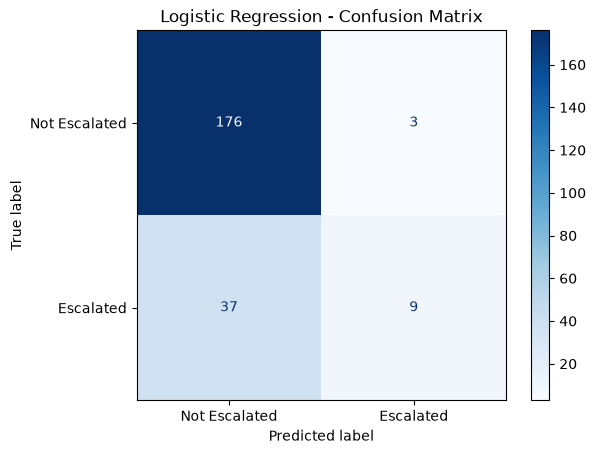

In [75]:
# Plot a confusion matrix and ROC curve for logistic regression

log_model = models["Logistic Regression"]

y_pred = log_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Escalated", "Escalated"]
)

disp.plot(cmap="Blues")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

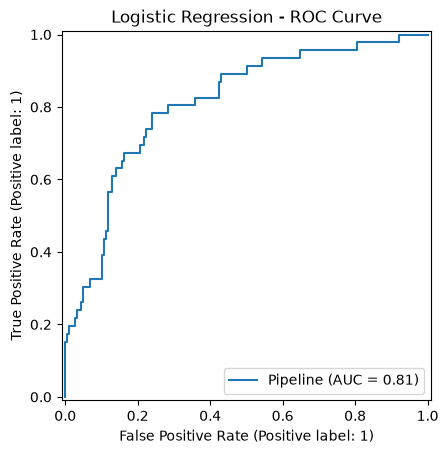

In [76]:
RocCurveDisplay.from_estimator(
    log_model,
    X_test,
    y_test
)

plt.title("Logistic Regression - ROC Curve")
plt.show()

In [78]:
# Evaluate thresholds 0.20, 0.30, 0.40, 0.50, 0.60, and 0.70,comparing results using metrics and our cost function

y_prob = log_model.predict_proba(X_test)[:, 1]

thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

threshold_results = []

for threshold in thresholds:

    y_pred_threshold = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred_threshold
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "F1": f1_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "FP": fp,
        "FN": fn,
        "Cost": 5 * fn + fp
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(3))

,Threshold,Precision,Recall,F1,FP,FN,Cost
0,0.2,0.429,0.783,0.554,48,10,98
1,0.3,0.549,0.609,0.577,23,18,113
2,0.4,0.571,0.261,0.358,9,34,179
3,0.5,0.750,0.196,0.310,3,37,188
4,0.6,1.000,0.065,0.122,0,43,215
5,0.7,0.000,0.000,0.000,0,46,230


In [79]:
#best threshold
best_threshold = threshold_df.loc[
    threshold_df["Cost"].idxmin()
]

print(best_threshold)

Threshold     0.200000
Precision     0.428571
Recall        0.782609
F1            0.553846
FP           48.000000
FN           10.000000
Cost         98.000000
Name: 0, dtype: float64


In [80]:
#Use stratified 5-fold cross-validation on the training set and tune k-NN's k over 5, 9, 15, 21, 
#and 31 using F1.
knn_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier())
])

param_grid = {
    "classifier__n_neighbors": [5, 9, 15, 21, 31]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)

print("Best cross-validation F1:", grid_search.best_score_)

cv_results = pd.DataFrame(grid_search.cv_results_)

display(
    cv_results[
        ["param_classifier__n_neighbors",
         "mean_test_score",
         "std_test_score",
         "rank_test_score"]
    ]
)


best_knn = grid_search.best_estimator_

knn_predictions = best_knn.predict(X_test)

print("Test F1:", f1_score(y_test, knn_predictions))


Best parameters: {'classifier__n_neighbors': 5}
Best cross-validation F1: 0.24329611908559276


,param_classifier__n_neighbors,mean_test_score,std_test_score,rank_test_score
0,5,0.243296,0.094565,1
1,9,0.197611,0.065219,2
2,15,0.159565,0.065455,3
3,21,0.145790,0.056372,4
4,31,0.112219,0.039743,5


Test F1: 0.2033898305084746


In [ ]:
                                                  ##Questions to Answer ##

#1.Why is accuracy alone potentially misleading?

#Because our dataset is imbalanced (79.33% non-escalated).
#A model predicting every ticket as non-escalated achieves approximately 79.6% accuracy but fails to identify any escalated tickets.

In [ ]:
#2. Which classifier has the strongest recall? Which has the strongest precision/F1?

#Strongest recall= Logistic Regression and LDA (0.196).
#Strongest precision= Logistic Regression and LDA (0.750).
#Strongest F1= Logistic Regression and LDA (0.310).

In [ ]:
#3. What changes when the threshold is lowered?

#Recall generally increases because more tickets are classified as escalated. 
#However, false positives increase and precision generally decreases.

In [ ]:
#4. Which threshold minimizes 5×FN + FP on the test set, and why might this estimate be optimistic if used repeatedly for tuning?

#Threshold 0.20 minimizes the cost, achieving 98 (5 × 10 + 48). 
#Repeatedly selecting thresholds using the test set causes overfitting to that test set, making the estimated performance potentially optimistic.

In [ ]:
#5.Explain prior, likelihood, posterior, and evidence using the ticket scenario.

#Prior: Probability of escalation before examining ticket features (20.67%).
#Likelihood: Probability of observing particular ticket features given that the ticket is escalated.
#Evidence: Overall probability of observing those ticket features.
#Posterior: Updated probability of escalation after considering the ticket features.

In [ ]:
#6.With posterior P(escalated|x) = 0.30, false-positive cost 1 and false-negative cost 5, 
#compare the expected cost of escalating and not escalating. Derive the cost-sensitive threshold.

#Escalate: (0.70 * 1 = 0.70).
#Do not escalate: (0.30 * 5 = 1.50).
#Therefore, escalating is the cheaper decision.
#The threshold is derived by equating the two expected costs:
#1(1-p)=5p
#p=1/6=0.167
#Thus, escalate when the predicted probability exceeds approximately 0.167.



In [ ]:
#7. model selection and deployment recommendation


#Based on the experimental results, Logistic Regression is the preferred classifier for the ticket-escalation prediction task.

#It achieved an accuracy of 0.822, precision of 0.750, recall of 0.196, F1-score of 0.310, and ROC-AUC of 0.811.

#Although Linear Discriminant Analysis achieved identical accuracy, precision, recall, and F1-score, Logistic Regression obtained a slightly higher ROC-AUC of 0.811 compared to 0.809. KNN with k=15 performed considerably worse, achieving an F1-score of 0.148. Hyperparameter tuning improved KNN's performance, with k=5 obtaining the highest cross-validation F1-score of approximately 0.243, although its test F1-score remained relatively low at 0.203. The majority-class baseline achieved 0.796 accuracy but failed to identify any escalated tickets, demonstrating why accuracy alone is insufficient for evaluating imbalanced classification problems.

#Threshold evaluation revealed an important trade-off between precision and recall. Lowering the classification threshold increased recall while also increasing false positives.

#At the default threshold of 0.50, Logistic Regression achieved a recall of only 0.196, meaning that most escalated tickets were missed. At a threshold of 0.20, recall increased to 0.783, identifying substantially more escalated tickets, although precision decreased to 0.429. Under the illustrative cost function of 5 × FN + FP, threshold 0.20 achieved the lowest observed total cost of 98, compared to 113 at threshold 0.30. Therefore, threshold 0.20 is preferred under the specified error-cost assumptions. This is also reasonably close to the theoretically derived cost-sensitive threshold of approximately 0.167.

#However, these results have limitations. The dataset is synthetic, and its patterns may not accurately represent real customer-support environments. Additionally, the probability estimates may require calibration, and selecting the threshold using the test set may produce an optimistic performance estimate. Further evaluation using independent real-world data is necessary.

#Before deployment, the model should undergo additional validation using unseen data, probability calibration checks, and monitoring for changes in data distributions and prediction performance. Potential biases affecting different customer groups should also be investigated. Human oversight should be maintained so that support personnel can review and override predictions when necessary. 

